# Pinecone: From Basics to Practical Vector Search and RAG

**A hands-on notebook | Beginner → Intermediate | Python + Pinecone + RAG**

**Learning outcomes.** By the end, you will understand vectors and similarity, Pinecone indexes, serverless configuration, namespaces, IDs, upsert/query/fetch/update/delete, metadata filtering, source-aware retrieval, integration with LangChain, and the basics of retrieval evaluation.

**Two tracks**

- **Track A: Offline fundamentals.** Runs without a Pinecone key. Uses small deterministic vector examples and local cosine similarity.
- **Track B: Pinecone cloud.** Real API exercises using the official `pinecone` SDK. Set `RUN_PINECONE=True` *only after* configuring your API key and checking pricing.

> **Costs and safety:** Creating an index, upserting vectors, running searches, and model inference can incur charges. Never paste API keys into notebooks or commit `.env`. The notebook defaults to no cloud calls, and cleanup code targets only the tutorial's namespace.

**Prerequisites:** Python 3.10+, Jupyter, basic Python. Internet and a Pinecone API key are required only for Track B.

## 0. The overall architecture

Pinecone is a managed search/index service for vector records. **The embedding model creates a vector; Pinecone stores and searches it.** A vector cannot ordinarily be decoded back into its original sentence. Store the original text (or a document pointer) in metadata so a RAG system can retrieve it.

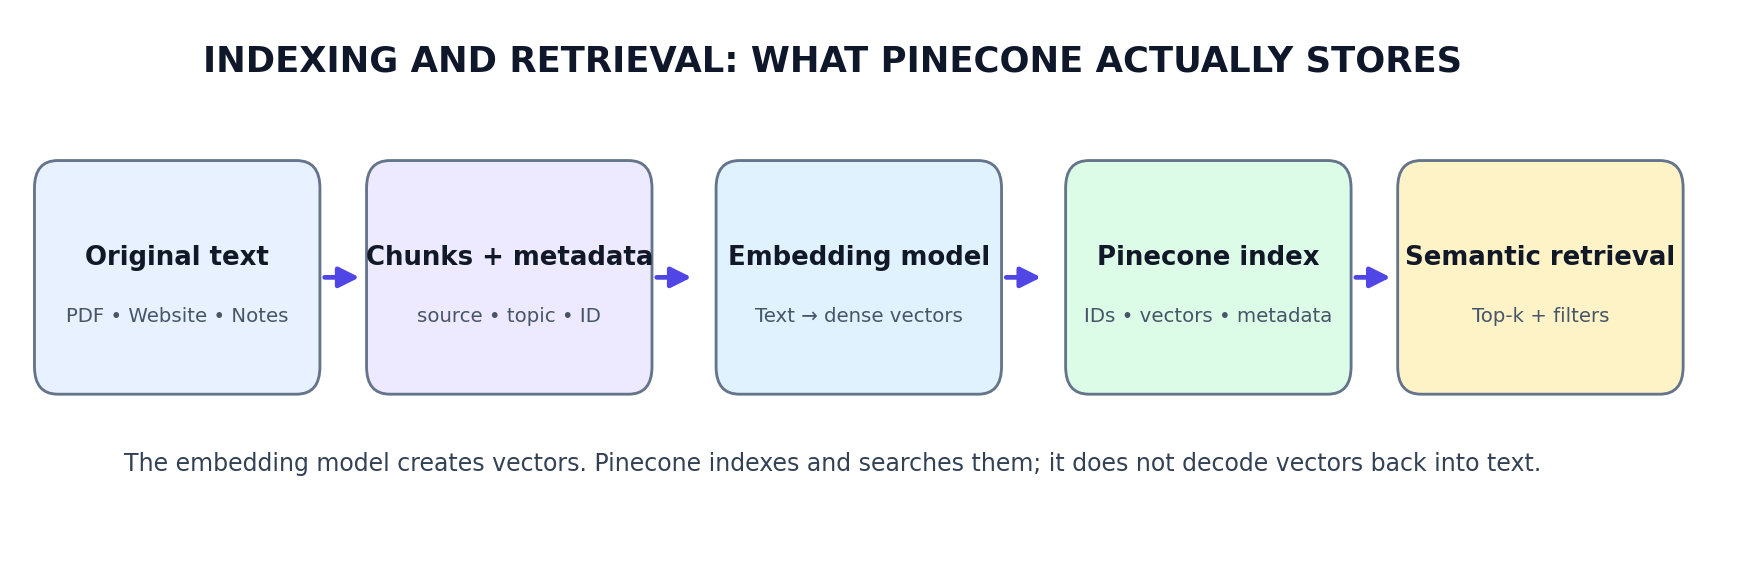

### What is stored in a vector record?

```python
{"id": "policy-001", "values": [0.12, -0.02, ...], "metadata": {"topic": "policies", "text": "...", "source": "policy.pdf"}}
```

**Index** = vector search configuration and collection; **namespace** = logical partition; **record** = unique ID + vector + optional metadata. The record ID is unique inside its namespace. Many production systems keep authoritative documents elsewhere and store only a pointer plus small snippets in Pinecone.

### What is Stored in a Vector Database Record (e.g., Pinecone)?

A vector database record in systems like Pinecone stores a mathematical representation of your data alongside its original context and filtering tags. Instead of storing traditional relational rows, it is optimized for high-speed similarity search in Retrieval-Augmented Generation (RAG) pipelines.

* **Unique Identifier (ID):** A distinct string (e.g., `"chunk-18"`) that uniquely identifies the specific segment of data within the index.
* **Dense Vector (Values):** The core component. It is a high-dimensional array of floating-point numbers generated by an embedding model that captures the semantic meaning of the text.
* **Metadata:** A JSON-like dictionary containing the raw text chunk and contextual tags (like the source document, date, or category). Storing the raw text allows the retriever to instantly pass readable content back to the LLM, while tags enable precise filtering before the vector search runs.
* **Sparse Values (Optional):** For systems utilizing hybrid search, records can also store sparse vectors (such as BM25 keyword weights) alongside the dense vector to ensure exact keyword matches are preserved.

#### Example Pinecone Record (JSON)
```json
{
  "id": "chunk-18",
  "values": [0.14, -0.02, 0.38, 0.05, -0.11],
  "sparse_values": {
    "indices": [482, 109],
    "values": [1.5, 0.8]
  },
  "metadata": {
    "source": "kubernetes-pod-troubleshooting.md",
    "text": "To update pod memory without rebooting nodes, patch the resource limits...",
    "category": "technical-support",
    "timestamp": "2026-11-04"
  }
}

## 1. Install dependencies

Run the installation cell once, restart the kernel if Python requests it, then execute the cells in order. The official modern SDK package is **`pinecone`**, not the legacy `pinecone-client` package. The local demo uses NumPy and scikit-learn for transparent calculations.

In [11]:
# Uncomment once to install the tutorial dependencies in your active notebook environment.
#%pip install -U pinecone python-dotenv numpy pandas matplotlib scikit-learn
# Optional for the last integration section:
# %pip install -U langchain-pinecone langchain-huggingface langchain-text-splitters sentence-transformers

import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

load_dotenv()
print("Python environment ready. NumPy:", np.__version__)

## 2. Embeddings are coordinates, not encoded text

Try a tiny 3-dimensional vector space. The values are **illustrative only**, not outputs from a real language embedding model. Cosine similarity compares the direction of two vectors:

\[\operatorname{cos}(q,d)=\frac{q\cdot d}{\|q\|\,\|d\|}\]

A cosine similarity near 1 means similar directions. It does **not** prove that the content is factually correct.

In [12]:
# Toy vectors selected to make cosine similarity easy to inspect.
toy_vectors = {
    "agentic rag": np.array([0.95, 0.10, 0.05], dtype=float),
    "vector database": np.array([0.85, 0.20, 0.02], dtype=float),
    "dark photon": np.array([0.05, 0.95, 0.10], dtype=float),
    "weather": np.array([0.02, 0.04, 0.99], dtype=float),
}
query_vector = np.array([1.0, 0.0, 0.0], dtype=float)

def cosine(a, b):
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

scores = pd.DataFrame([
    {"topic": topic, "cosine_similarity": cosine(query_vector, vector)}
    for topic, vector in toy_vectors.items()
]).sort_values("cosine_similarity", ascending=False)
display(scores)

,topic,cosine_similarity
0,agentic rag,0.993146
1,vector database,0.973162
2,dark photon,0.052271
3,weather,0.020181


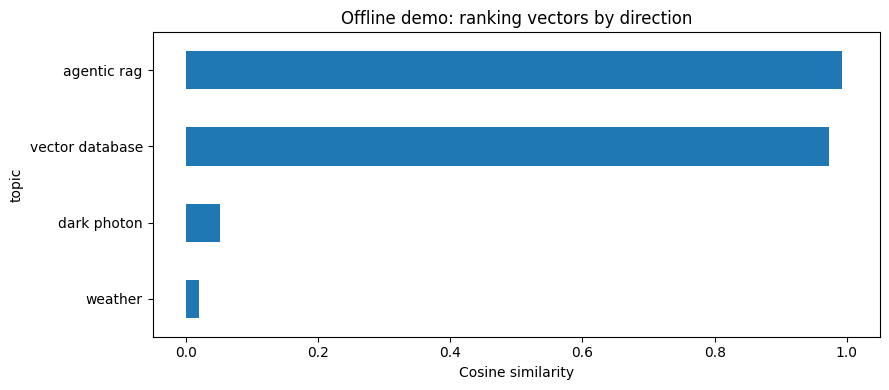

In [13]:
# Plot the scores from the previous cell (illustrative vectors).
ax = scores.sort_values("cosine_similarity").plot.barh(
    x="topic", y="cosine_similarity", figsize=(9, 4), legend=False
)
ax.set_xlim(-0.05, 1.05)
ax.set_xlabel("Cosine similarity")
ax.set_title("Offline demo: ranking vectors by direction")
plt.tight_layout()
plt.show()

**Exercise:** Change `query_vector` to `[0, 1, 0]`. Which topic becomes closest? Why?

## 3. Dense vector dimensions and model consistency

A Pinecone index expects a fixed dimension. **Every vector upserted and queried must match that dimension.** If you change embedding models, you generally need a new index (or a planned migration and full re-embedding).

We use **384 dimensions** as an example, matching `sentence-transformers/all-MiniLM-L6-v2`. In an actual project, verify your embedding model's output dimension instead of guessing.

In [14]:
# Works offline; validates the concept before creating a cloud index.
DIMENSION = 384
fake_vector = np.zeros(DIMENSION, dtype=np.float32)
assert len(fake_vector) == DIMENSION
print(f"Sample vector shape: {fake_vector.shape}")

# Deliberate failure: this must never be used to upsert into a 384-dimensional index.
wrong_vector = [0.1, 0.2, 0.3]
print("Would dimension validation pass?", len(wrong_vector) == DIMENSION)

Sample vector shape: (384,)
Would dimension validation pass? False


## 4. Pinecone's hierarchy: index, namespace, record

Use **one index per embedding configuration and access pattern**, not an index per document. Namespaces can separate tenants, environments, or document groups. A metadata field can carry topics, source IDs, timestamps, versions, or visibility tags. **Do not treat namespaces or metadata filters as your only authorization mechanism.**

```text
Pinecone Project
    |
    └── Index: company-rag
          |
          ├── Namespace: policies
          |     ├── Vector 001 + Metadata
          |     └── Vector 002 + Metadata
          |
          ├── Namespace: pricing
          |     ├── Vector 003 + Metadata
          |     └── Vector 004 + Metadata
          |
          └── Namespace: profile
                └── Vector 005 + Metadata
```

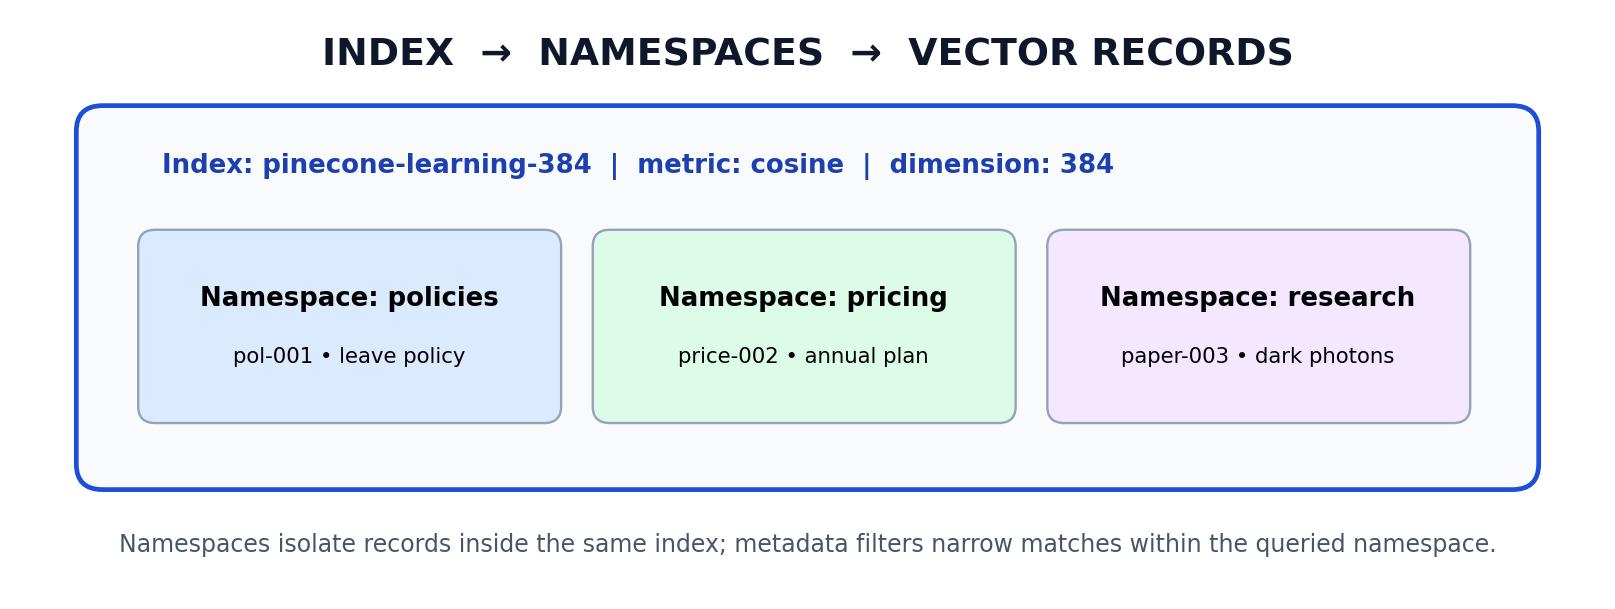

### Configuration used throughout the cloud exercises

This notebook uses a dedicated tutorial index name and two namespaces. `RUN_PINECONE` is `False` by default so later cells remain safe to run without credentials. We use client-side embeddings: the embedding model is **not** hosted by Pinecone in this tutorial.

In [17]:
from pathlib import Path
import os
from dotenv import load_dotenv

load_dotenv()

# Change to True only after configuring PINECONE_API_KEY and reviewing cloud charges.
#RUN_PINECONE = False
RUN_PINECONE = True
INDEX_NAME = os.getenv("PINECONE_TUTORIAL_INDEX", "pinecone-learning-384")
CLOUD = "aws"
REGION = "us-east-1"  # Change if your project/plan requires a different supported region.
NAMESPACE = "tutorial-v1"
OTHER_NAMESPACE = "tutorial-other"
pinecone_API = os.getenv("PINECONE_API_KEY")

if RUN_PINECONE and not pinecone_API:
    raise RuntimeError("Set PINECONE_API_KEY in .env before enabling cloud calls.")

print({"cloud_calls_enabled": RUN_PINECONE, "index": INDEX_NAME,
       "namespace": [NAMESPACE, OTHER_NAMESPACE], "dimension": DIMENSION})

{'cloud_calls_enabled': True, 'index': 'pinecone-learning-384', 'namespace': 'tutorial-v1', 'dimension': 384}


## 5. Connect to Pinecone and create a serverless index

The SDK client manages indexes. Creating an index can be asynchronous, so check `status.ready` before using it. Reusing an existing index is safe **only when its dimension and metric agree with your embedding setup**.

In production, target an index through its returned host. Here we obtain that host from `describe_index`.

In [16]:
# OFF by default. Set RUN_PINECONE=True in the earlier configuration cell.
pc = None
index = None
if RUN_PINECONE:
    from pinecone import Pinecone, ServerlessSpec
    import time

    #pc = Pinecone(api_key=os.environ["PINECONE_API_KEY"])
    pc = Pinecone(api_key=pinecone_API)
    existing_names = set(pc.list_indexes().names())
    if INDEX_NAME not in existing_names:
        pc.create_index(
            name=INDEX_NAME,
            dimension=DIMENSION,
            metric="cosine",
            spec=ServerlessSpec(cloud=CLOUD, region=REGION),
        )
    # Wait for the control-plane status to report readiness (bounded wait).
    for _ in range(30):
        description = pc.describe_index(INDEX_NAME)
        if description.status.ready:
            break
        time.sleep(2)
    else:
        raise TimeoutError("Index was not ready within 60 seconds; inspect the Pinecone console.")
    if description.dimension != DIMENSION or description.metric != "cosine":
        raise ValueError("Existing index configuration does not match this tutorial.")

    index = pc.Index(host=description.host)
    print("Connected:", description.host)
else:
    print("Cloud section skipped. Enable RUN_PINECONE to create or connect to an index.")

Connected: https://pinecone-learning-384-yehr0x9.svc.aped-4627-b74a.pinecone.io


## 6. Make REAL embeddings locally (optional model download)

The sentence-transformer downloads model weights on first use. This is independent of Pinecone. Keep the same model for document and query embeddings. If downloading is blocked, you can continue the offline sections and return later.

In [19]:
# This section is optional to avoid automatic model downloads.
RUN_LOCAL_EMBEDDINGS = True
model = None

if RUN_LOCAL_EMBEDDINGS or RUN_PINECONE:
    from sentence_transformers import SentenceTransformer
    model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
    probe = model.encode("What is a vector database?")
    assert len(probe) == DIMENSION, f"Expected {DIMENSION}, got {len(probe)}"
    print("Real embedding dimensions:", len(probe))
else:
    print("Real embedding model not loaded. Set RUN_LOCAL_EMBEDDINGS=True to test it.")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Real embedding dimensions: 384


## 7. Upsert: add or replace records

**Upsert** means *insert if the ID is new, replace if it already exists in that namespace*. Every vector record has an ID, numeric values of the index dimension, and optional metadata. In RAG, preserve the source and original text as metadata or store a reliable external content reference.

The examples use a small, synthetic company-knowledge collection, so you can safely experiment without private files.

In [20]:
sample_docs = [
    {"id": "pol-001", "text": "Employees can request annual leave through the HR portal.", "category": "policy", "source": "policies.md"},
    {"id": "pol-002", "text": "Remote work requires manager approval for designated roles.", "category": "policy", "source": "policies.md"},
    {"id": "price-001", "text": "The Starter plan costs 12 USD per month in this demo.", "category": "pricing", "source": "pricing.md"},
    {"id": "price-002", "text": "Annual subscription cancellation takes effect at the renewal date in this demo.", "category": "pricing", "source": "pricing.md"},
    {"id": "tech-001", "text": "Agentic RAG can use a retriever and a relevance evaluator before generation.", "category": "technical", "source": "tech.md"},
    {"id": "tech-002", "text": "Pinecone is a vector search database that stores embeddings and metadata.", "category": "technical", "source": "tech.md"},
]
records_df = pd.DataFrame(sample_docs)
display(records_df)

# Embeddings are intentionally optional. We do not send zero or random vectors to Pinecone.
if RUN_PINECONE:
    assert model is not None and index is not None
    vectors = model.encode([d["text"] for d in sample_docs], normalize_embeddings=True)
    upsert_records = [
        {"id": d["id"], "values": vec.tolist(),
         "metadata": {"text": d["text"], "category": d["category"], "source": d["source"]}}
        for d, vec in zip(sample_docs, vectors)
    ]
    
    result = index.upsert(vectors=upsert_records, namespace=NAMESPACE)
    print("Upsert result:", result)

,id,text,category,source
0,pol-001,Employees can request annual leave through the...,policy,policies.md
1,pol-002,Remote work requires manager approval for desi...,policy,policies.md
2,price-001,The Starter plan costs 12 USD per month in thi...,pricing,pricing.md
3,price-002,Annual subscription cancellation takes effect ...,pricing,pricing.md
4,tech-001,Agentic RAG can use a retriever and a relevanc...,technical,tech.md
5,tech-002,Pinecone is a vector search database that stor...,technical,tech.md


Upsert result: UpsertResponse(upserted_count=6)


## 8. Query vectors and Top-k semantic search

You must embed the **user query with the same model** used for document vectors. A query response contains IDs, similarity scores, and metadata if requested. For a cosine index, a higher score generally means closer vector directions, but **score is not a calibrated probability or a factuality score**.

In [21]:
QUERY = "Which subscription is billed monthly?"
TOP_K = 3

if RUN_PINECONE:
    assert model is not None and index is not None
    query_embedding = model.encode(QUERY, normalize_embeddings=True).tolist()
    result = index.query(
        vector=query_embedding,
        namespace=NAMESPACE,
        top_k=TOP_K,
        include_metadata=True,
        include_values=False,
    )
    matches = [
        {"id": m.id, "score": m.score,
         "source": (m.metadata or {}).get("source"),
         "text": (m.metadata or {}).get("text", "")}
        for m in result.matches
    ]
    display(pd.DataFrame(matches))
else:
    print("Example query:", QUERY)
    print("Run the cloud section to search your Pinecone index.")

,id,score,source,text
0,price-001,0.477736,pricing.md,The Starter plan costs 12 USD per month in thi...
1,price-002,0.461622,pricing.md,Annual subscription cancellation takes effect ...
2,pol-001,0.184267,policies.md,Employees can request annual leave through the...


## 9. Filtering by metadata

Pinecone can search *within* a namespace while restricting candidate records using metadata fields. Filters are useful for content categories, customers, time windows, or compliance flags. They are **not a substitute for permission checks before retrieval**.

In [22]:
# Compare a general search with a filtered search limited to pricing documents.
if RUN_PINECONE:
    filtered = index.query(
        vector=query_embedding,
        namespace=NAMESPACE,
        top_k=3,
        filter={"category": {"$eq": "pricing"}},
        include_metadata=True,
    )
    display(pd.DataFrame([
        {"id": m.id, "score": m.score, "category": m.metadata.get("category"),
         "text": m.metadata.get("text")}
        for m in filtered.matches
    ]))
else:
    display(records_df[records_df["category"] == "pricing"])
    print("This local table illustrates the filter; the live filter runs in Pinecone.")

,id,score,category,text
0,price-001,0.477926,pricing,The Starter plan costs 12 USD per month in thi...
1,price-002,0.462718,pricing,Annual subscription cancellation takes effect ...


## 10. Query a second namespace

Namespaces live in the same index but their records are separate. You can reuse IDs across namespaces without collision. Searches target **one namespace at a time** in this direct-query example.

In [23]:
if RUN_PINECONE:
    # Insert one demonstration record in a different namespace.
    other_text = "This namespace stores an isolated research note on dark photons."
    other_vec = model.encode(other_text, normalize_embeddings=True).tolist()
    index.upsert(vectors=[{
        "id": "research-001", "values": other_vec,
        "metadata": {"text": other_text, "category": "research", "source": "research.md"}
    }], namespace=OTHER_NAMESPACE)

    other_results = index.query(vector=other_vec, top_k=2,
                                namespace=OTHER_NAMESPACE, include_metadata=True)
    print([(m.id, round(m.score, 3)) for m in other_results.matches])
else:
    print(f"Namespace A: {NAMESPACE} | Namespace B: {OTHER_NAMESPACE}")

[('research-001', 1.0)]


## 11. Fetch, update, and delete by ID

Use stable deterministic IDs so you can re-ingest documents without generating duplicates. `fetch()` retrieves stored record data for IDs. `update()` can change values or metadata for an existing ID; `upsert()` replaces a record. `delete()` removes specified IDs. Avoid delete-all operations unless you understand the target namespace.

In [25]:
if RUN_PINECONE:
    fetched = index.fetch(ids=["pol-001", "price-001"], namespace=NAMESPACE)
    print("Fetched IDs:", list(fetched.vectors.keys()))

    # Add metadata to an existing record. Confirm changes with fetch.
    index.update(id="pol-001", set_metadata={"reviewed": True}, namespace=NAMESPACE)
    verified = index.fetch(ids=["pol-001"], namespace=NAMESPACE)
    print("Updated metadata:", verified.vectors["pol-001"].metadata)

    # Delete only one known tutorial record; rerun the upsert cell if you need it again.
    # index.delete(ids=["pol-002"], namespace=NAMESPACE)
else:
    print("Cloud CRUD calls disabled. Review the methods above, then enable Pinecone deliberately.")

Fetched IDs: ['pol-001', 'price-001']
Updated metadata: {'category': 'policy', 'source': 'policies.md', 'text': 'Employees can request annual leave through the HR portal.'}


## 12. Index statistics and eventual consistency

`describe_index_stats()` reports vector totals and namespace counts. Index operations may be eventually consistent: an immediate query after upsert/update/delete might not reflect the latest write. During ingestion, use retries and short backoff when verifying changes.

In [26]:
if RUN_PINECONE:
    stats = index.describe_index_stats()
    print("Total vectors:", stats.total_vector_count)
    print("Namespaces:", stats.namespaces)
else:
    print("Expected demo data: 6 records in tutorial-v1, optionally 1 in tutorial-other.")

Total vectors: 7
Namespaces: {'tutorial-v1': NamespaceSummary(vector_count=6), 'tutorial-other': NamespaceSummary(vector_count=1)}


## 13. Offline RAG without an API: TF-IDF retrieval

To practice the end-to-end *retrieval mechanism* without downloading a model or calling Pinecone, use a local TF-IDF matrix. **TF-IDF is sparse lexical retrieval, not a substitute for semantic embeddings.** It lets you test source metadata and top-k ranking in a fully runnable example.

In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity as sklearn_cosine

texts = [d["text"] for d in sample_docs]
lexical_model = TfidfVectorizer(stop_words="english")
X = lexical_model.fit_transform(texts)

def offline_search(question: str, k: int = 3):
    scores = sklearn_cosine(lexical_model.transform([question]), X)[0]
    order = np.argsort(scores)[::-1][:k]
    return [{"id": sample_docs[i]["id"], "score": float(scores[i]),
             "text": sample_docs[i]["text"], "source": sample_docs[i]["source"]}
            for i in order]

demo_hits = offline_search("How can employees request leave?", k=3)
display(pd.DataFrame(demo_hits))

,id,score,text,source
0,pol-001,0.727238,Employees can request annual leave through the...,policies.md
1,tech-002,0.000000,Pinecone is a vector search database that stor...,tech.md
2,tech-001,0.000000,Agentic RAG can use a retriever and a relevanc...,tech.md


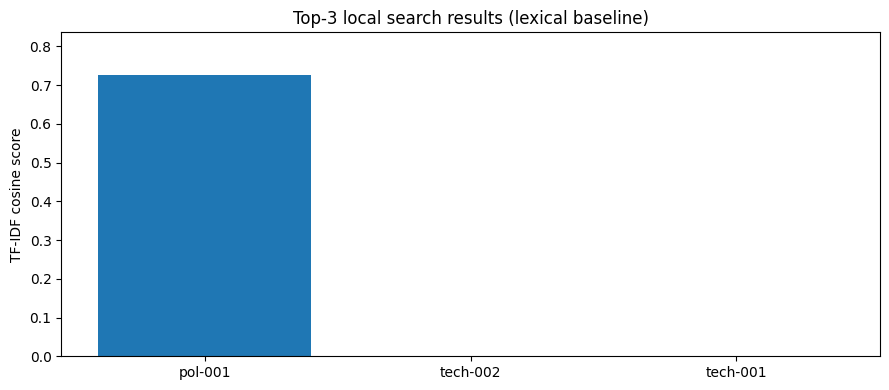

In [28]:
# Visualize retrieval strength in the offline example.
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar([r["id"] for r in demo_hits], [r["score"] for r in demo_hits])
ax.set_ylim(0, max(0.1, max(r["score"] for r in demo_hits) * 1.15))
ax.set_ylabel("TF-IDF cosine score")
ax.set_title("Top-3 local search results (lexical baseline)")
plt.tight_layout()
plt.show()

## 14. From Pinecone results to a grounded RAG prompt

Pinecone handles **retrieval**; a separate LLM handles **generation**. The prompt should expose short source-attributed passages and instruct the model to abstain when evidence is absent. A real system additionally needs access controls, document versioning, answer evaluation, and citation checks.

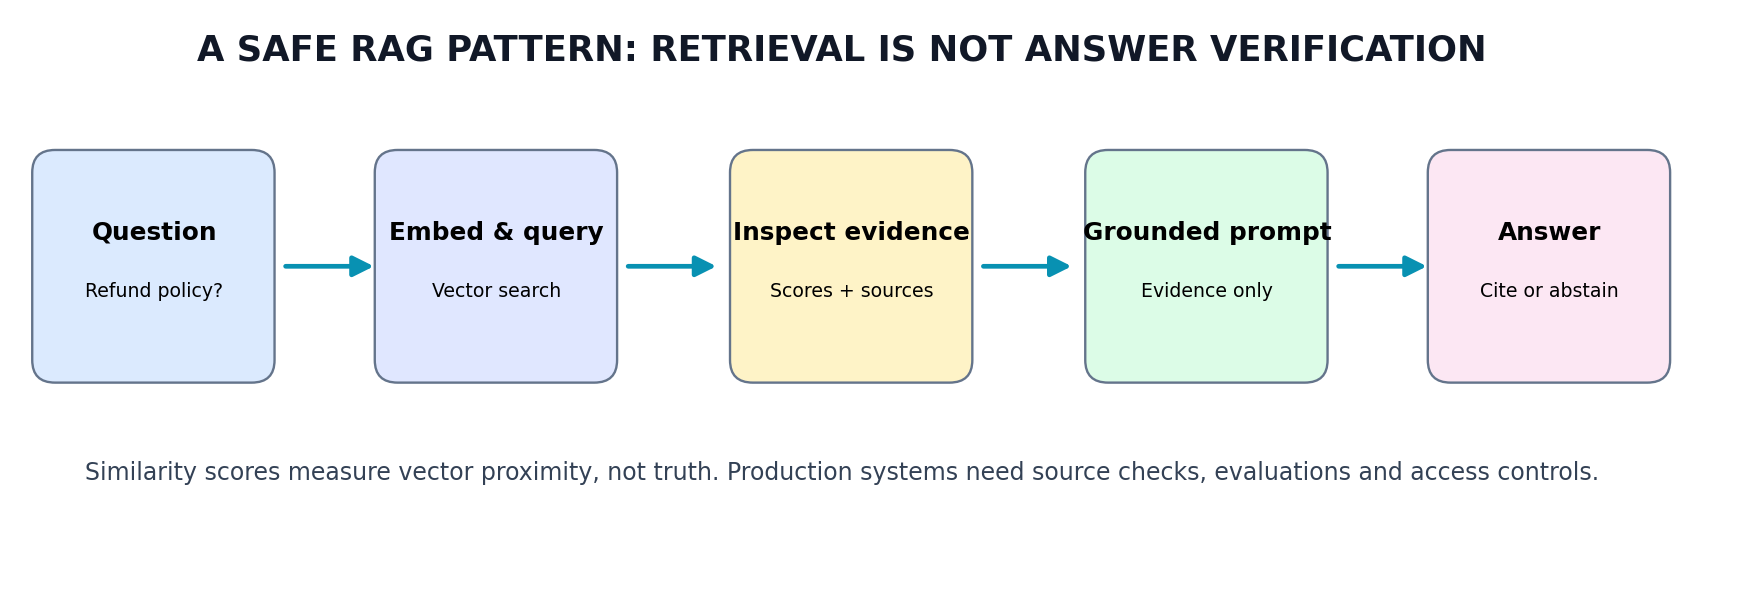

In [ ]:
def build_context(hits):
    return "\n\n".join(
        f"[Source: {h['source']} | ID: {h['id']}]\n{h['text']}" for h in hits
    )

def build_grounded_messages(question: str, hits):
    context = build_context(hits)
    return [
        {"role": "system", "content": (
            "You answer from the provided excerpts only. Cite the source filename for every factual claim. "
            "If the excerpts do not support an answer, say that the information is unavailable."
        )},
        {"role": "user", "content": f"Question: {question}\n\nEvidence:\n{context}"},
    ]

question = "How do employees request annual leave?"
hits = offline_search(question)
messages = build_grounded_messages(question, hits)
print(messages[1]["content"])

# Optional: with OpenAI configured, pass messages to a chat model (additional API fees).
# from langchain_openai import ChatOpenAI
# answer = ChatOpenAI(model="gpt-4o-mini", temperature=0).invoke(messages)
# print(answer.content)

## 15. Retrieval evaluation: Recall@k

A high similarity score does **not** prove the right passage was retrieved. Make a small golden evaluation set containing queries and known relevant record IDs. **Recall@k** measures the fraction of relevant IDs appearing within the top-k returned IDs.

\[\mathrm{Recall@k}=\frac{|\mathrm{Relevant}\cap\mathrm{RetrievedTopK}|}{|\mathrm{Relevant}|}\]

For a real evaluation, create representative queries from actual users, review gold labels manually, and avoid tuning the retrieval system on the held-out test questions.

In [ ]:
# Illustrative relevance labels for the six synthetic records.
gold = [
    ("How do employees request annual leave?", {"pol-001"}),
    ("What is the monthly price of the Starter plan?", {"price-001"}),
    ("Does remote work require approval?", {"pol-002"}),
    ("What is the Pinecone vector database?", {"tech-002"}),
]

def recall_at_k(retrieved_ids, relevant_ids):
    return len(set(retrieved_ids) & set(relevant_ids)) / len(relevant_ids)

rows = []
for q, relevant in gold:
    hits = offline_search(q, k=3)
    rows.append({"query": q, "recall@1": recall_at_k([h["id"] for h in hits[:1]], relevant),
                 "recall@3": recall_at_k([h["id"] for h in hits[:3]], relevant)})
metrics = pd.DataFrame(rows)
display(metrics)
print("Mean recall@1:", round(metrics["recall@1"].mean(), 3))
print("Mean recall@3:", round(metrics["recall@3"].mean(), 3))

In [ ]:
# Plot an aggregate offline retrieval evaluation.
means = metrics[["recall@1", "recall@3"]].mean()
ax = means.plot.bar(figsize=(7, 4), rot=0)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Mean recall")
ax.set_title("Toy benchmark: lexical retrieval Recall@k")
plt.tight_layout()
plt.show()

## 16. Intermediate: using Pinecone with LangChain

The `PineconeVectorStore` integration is convenient for RAG application code, while the **raw SDK** is better for learning index operations and managing fine-grained control. Use a matching embedding model and the same namespace. This cell is intentionally optional and requires additional packages.

In [ ]:
# Optional LangChain integration, using the SAME index and namespace.
# Run only after installing langchain-pinecone and langchain-huggingface.
if RUN_PINECONE:
    from langchain_pinecone import PineconeVectorStore
    from langchain_huggingface import HuggingFaceEmbeddings

    lc_embeddings = HuggingFaceEmbeddings(
        model_name="sentence-transformers/all-MiniLM-L6-v2",
        encode_kwargs={"normalize_embeddings": True},
    )
    lc_store = PineconeVectorStore(
        index_name=INDEX_NAME,
        embedding=lc_embeddings,
        namespace=NAMESPACE,
    )
    lc_hits = lc_store.similarity_search("What is Agentic RAG?", k=3)
    for d in lc_hits:
        print(d.metadata.get("source"), "→", d.page_content[:140])
else:
    print("LangChain + Pinecone integration disabled (no network calls).")

## 17. Production considerations and common mistakes

| Risk | What to do |
|---|---|
| Embedding dimension mismatch | Verify dimension before creating the index; re-embed for a new model |
| Mixing embedding models | Keep ingestion and query encoders consistent |
| Querying wrong namespace | Log the index host, namespace, model version, and document version |
| Storing private content in metadata | Minimize sensitive fields, enforce ACLs outside vector search, review retention |
| Assuming scores mean truth | Add provenance, reranking, support checks, and evaluated answer quality |
| Duplicate or stale chunks | Use stable IDs and version-aware ingestion/deletion |
| Immediate queries miss recent upserts | Handle eventual consistency with bounded retry/backoff |
| Unchecked cloud expense | Start small, watch limits and usage, clean tutorial resources deliberately |
| Dangerous index deletion | Explicitly name and inspect target index; never delete shared indexes by default |
| Documentation/version drift | Verify your installed SDK and official docs before upgrading production code |

**Other important topics for further study:** sparse/hybrid retrieval, rerankers, cross-encoder evaluation, batching, async indexing, integrated embedding indexes, schema/indexing constraints, multitenant isolation, performance tracing, and cost/unit accounting.

## 18. Optional cleanup (destructive; disabled)

The code below deletes only the tutorial namespaces. **Do not enable it if you changed namespace names to production data.** Index deletion is deliberately excluded.

In [ ]:
# WARNING: Destructive. Explicitly opt in after confirming target namespaces.
CONFIRM_DELETE_TUTORIAL_NAMESPACES = False
if RUN_PINECONE and CONFIRM_DELETE_TUTORIAL_NAMESPACES:
    assert NAMESPACE.startswith("tutorial-") and OTHER_NAMESPACE.startswith("tutorial-")
    index.delete(delete_all=True, namespace=NAMESPACE)
    index.delete(delete_all=True, namespace=OTHER_NAMESPACE)
    print("Deleted only the two tutorial namespaces (may be eventually consistent).")
else:
    print("No data was deleted.")

## 19. Exercises and mini-project

**Exercise A (starter):** Add two more synthetic policy documents, re-upsert them, and compare top-1 vs top-3 query results.

**Exercise B (intermediate):** Add metadata `department` and filter queries to the HR department. Verify whether the relevance of results improves for HR questions.

**Exercise C (intermediate):** Compare one embedding model against another using separate Pinecone indexes (dimensions may differ). Keep identical evaluation queries and report Recall@k and cost.

**Mini-project:** Build a company-policy QA assistant using a handful of public or synthetic PDFs. Store `source`, `page`, `document_id`, and version for each chunk; retrieve from Pinecone; build citations; evaluate 25 questions; compare baseline top-k and a reranked pipeline. Do not claim a production-quality system without tests.

**Checkpoint:** Explain in your own words the difference between embedding, index, namespace, metadata filter, and LLM answer generation.

## 20. Reference documentation

- [Pinecone documentation](https://docs.pinecone.io/)
- [Pinecone Python SDK reference](https://docs.pinecone.io/reference/python-sdk)
- [Pinecone index and data operations](https://docs.pinecone.io/guides/indexes/create-an-index)
- [Pinecone data management](https://docs.pinecone.io/guides/manage-data/upsert-data)
- [Pinecone search](https://docs.pinecone.io/guides/search/search-overview)
- [LangChain Pinecone integration](https://docs.langchain.com/oss/python/integrations/vectorstores/pinecone)

**Version note (November 2026):** Pinecone's SDK and API evolve. The code follows the common current `Pinecone`, `ServerlessSpec`, and index methods. Check the SDK docs for differences in your installed version and account region/plan before executing cloud cells.

# FAISS vs ChromaDB vs Pinecone: Vector Database Comparison



## 1. Introduction

**FAISS, ChromaDB, and Pinecone** are widely used for vector similarity search in Retrieval-Augmented Generation (RAG) systems. All three help retrieve relevant information using embeddings, but they differ significantly in architecture, scalability, persistence, and operational complexity.

- **FAISS (Facebook AI Similarity Search):** An open-source library developed by Meta for efficient vector similarity search.
- **ChromaDB:** An open-source, developer-friendly vector database that stores embeddings, documents, and metadata.
- **Pinecone:** A managed cloud vector database designed for scalable retrieval applications.

## 2. Feature Comparison

| Feature | FAISS | ChromaDB | Pinecone |
|---|---|---|---|
| **Type** | Vector search library | Vector database | Managed vector database |
| **Primary deployment** | Local / self-hosted | Local, self-hosted, cloud | Cloud-managed |
| **Open source** | Yes | Yes (core) | No (managed service) |
| **Setup difficulty** | Easy | Very easy | Easy, requires cloud setup |
| **Persistent storage** | Manual index saving | Built-in persistent mode | Managed persistence |
| **Metadata filtering** | Limited natively | Yes | Yes |
| **Document storage** | External storage required | Built-in | Record metadata / text fields |
| **GPU acceleration** | Yes | Deployment-dependent | Managed infrastructure |
| **Scaling** | Developer-managed | Local or distributed/cloud | Managed scaling |
| **Hybrid search** | Requires additional components | Supported | Supported |
| **Namespaces / collections** | Indexes and custom logic | Collections | Namespaces |
| **Infrastructure management** | Developer | Developer or provider | Provider |
| **API key required** | No | Not for local use | Yes |
| **Cost model** | Free library + infrastructure | Free local / paid cloud | Usage-based cloud pricing |
| **Best suited for** | Research and custom search | Prototypes and local RAG | Managed production RAG |

**Note:** Actual retrieval speed and capacity depend on dataset size, index configuration, embedding dimensions, hardware, network latency, and workload. No system is universally fastest.

## 3. Architecture Differences

### FAISS

```text
Documents
    ↓
Embedding Model
    ↓
Vector Embeddings
    ↓
FAISS Index (Local)
    ↓
Similarity Search
    ↓
Top-k Vector IDs
    ↓
Original Text (External Store)
```

FAISS focuses on fast nearest-neighbor search. Applications must manage document text, metadata, and database-like functionality separately, although frameworks such as LangChain can provide convenient wrappers.

### ChromaDB

```text
Documents
    ↓
Embedding Model
    ↓
Chroma Collection
    ├── Embeddings
    ├── Documents
    ├── Metadata
    └── IDs
    ↓
Similarity + Metadata Search
    ↓
Relevant Documents
```

Chroma provides integrated document storage, filtering, and vector retrieval, making it convenient for developing RAG applications.

### Pinecone

```text
Documents
    ↓
Text Chunking
    ↓
Embedding Model
    ↓
Pinecone Cloud Index
    ├── Vector Records
    ├── Metadata
    └── Namespaces
    ↓
Vector Search API
    ↓
Relevant Chunks
    ↓
LLM
```

Pinecone manages the vector database infrastructure, allowing developers to focus on ingestion, retrieval, and application logic.

## 4. Python Examples

The following examples use the same embedding model for a fair comparison.

```python
%pip install -U langchain-community langchain-chroma langchain-pinecone langchain-huggingface faiss-cpu chromadb pinecone sentence-transformers
```

### A. FAISS

```python
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

texts = [
    "Agentic RAG uses agents to control retrieval.",
    "Corrective RAG evaluates document relevance.",
    "Graph RAG retrieves relationships between entities."
]

db = FAISS.from_texts(texts, embeddings)

results = db.similarity_search(
    "What is Agentic RAG?",
    k=2
)

for doc in results:
    print(doc.page_content)
```

### B. ChromaDB

```python
from langchain_chroma import Chroma

db = Chroma.from_texts(
    texts=texts,
    embedding=embeddings,
    collection_name="rag_tutorial",
    persist_directory="./chroma_db"
)

results = db.similarity_search(
    "What is Agentic RAG?",
    k=2
)

for doc in results:
    print(doc.page_content)
```

Chroma stores the collection locally in `./chroma_db`.

### C. Pinecone

```python
import os
from dotenv import load_dotenv
from pinecone import Pinecone, ServerlessSpec
from langchain_pinecone import PineconeVectorStore

load_dotenv()

pc = Pinecone(api_key=os.environ["PINECONE_API_KEY"])

index_name = "rag-tutorial"

if not pc.has_index(index_name):
    pc.create_index(
        name=index_name,
        dimension=384,
        metric="cosine",
        spec=ServerlessSpec(
            cloud="aws",
            region="us-east-1"
        )
    )

db = PineconeVectorStore.from_texts(
    texts=texts,
    embedding=embeddings,
    index_name=index_name,
    namespace="tutorial"
)

results = db.similarity_search(
    "What is Agentic RAG?",
    k=2
)

for doc in results:
    print(doc.page_content)
```

**Important:** The index dimension (384) must match the output dimension of `all-MiniLM-L6-v2`. Pinecone also requires an available index and a valid API key, and cloud operations may incur charges.

## 5. Strengths and Limitations

| System | Main strengths | Main limitations |
|---|---|---|
| **FAISS** | Fast local search, GPU support, extensive indexing algorithms, no cloud dependency | No built-in full database service; scaling, metadata, and persistence management require extra work |
| **ChromaDB** | Simple integration, persistent collections, document and metadata support, local development | Self-hosted scaling and operations require planning |
| **Pinecone** | Managed infrastructure, scalable search, namespaces, filtering, hosted APIs | Cloud dependency, usage costs, network latency, reduced infrastructure control |

## 6. Which One Should You Choose?

| Project scenario | Recommended choice | Reason |
|---|---|---|
| Learning vector similarity search | **FAISS** | Simple and efficient for understanding embeddings |
| Research experiments | **FAISS** | Extensive ANN algorithms and fine-grained index control |
| Local PDF chatbot | **ChromaDB** | Built-in persistence, documents, and metadata |
| Local agentic RAG prototype | **ChromaDB** | Easy integration without managed cloud infrastructure |
| Managed production RAG | **Pinecone** | Cloud-managed indexing, retrieval, and scaling |
| Multi-tenant hosted application | **Pinecone or Chroma Cloud** | Managed infrastructure and logical data isolation |
| Offline environment | **FAISS or local ChromaDB** | No mandatory external retrieval service |
| Large custom GPU search workload | **FAISS** | Direct access to optimized GPU-based similarity search |

## 7. Engineering Recommendation

For learning and implementing Agentic RAG, a practical progression is:

**FAISS → ChromaDB → Pinecone**

1. Start with **FAISS** to understand vector indexing and similarity search.
2. Use **ChromaDB** to learn persistent collections, metadata filtering, and document management.
3. Move to **Pinecone** to understand cloud-based retrieval, namespaces, managed scaling, and operational costs.

However, migrating to Pinecone does not automatically improve retrieval accuracy. Accuracy depends heavily on the embedding model, chunking strategy, retrieval method, reranking, and evaluation dataset.

## 8. Key Takeaway

**FAISS is a search engine component, ChromaDB is a developer-friendly vector database, and Pinecone is a managed cloud vector database.**

The best choice depends on the requirements of the application:

- **FAISS:** Maximum control over similarity search.
- **ChromaDB:** Convenience for local development and document-based RAG.
- **Pinecone:** Managed infrastructure for cloud-based RAG systems.

For a professional RAG system, benchmark **Recall@k, MRR, query latency, indexing throughput, and cost** before selecting the final vector database.

### References

- [FAISS Documentation](https://faiss.ai/)
- [ChromaDB Documentation](https://docs.trychroma.com/)
- [Pinecone Documentation](https://docs.pinecone.io/)